<a href="https://colab.research.google.com/github/JulyAtaides/IA_-KADIDJA-/blob/main/atividades/atividade-07-aprendizado-supervisionado/fila_de_cadastros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade 7 — Sistema especialista com aprendizado supervisionado

**Disciplina:** Inteligência Artificial, Linguagens Formais e Autômatos  
**Professora:** Kadidja Valéria  
**Aluna:** Julyane Ataides · Turma N1  
**Aula 13** · 09/11/2026

> Usei a minha parte do projeto do squad 5 (o repositório de TCCs da UDF). No squad eu fiquei com o **cadastro** e a **validação de cadastro** (BL-11 e BL-12), então a minha atividade é sobre a **fila de cadastros** que o administrador precisa analisar.

## O problema

No repositório, qualquer pessoa com e-mail `@cs.udf.edu.br` pode se cadastrar, mas o cadastro nasce **não validado** (RN-03). O administrador abre a lista de cadastros pendentes e decide:

- **validar**: escolhe pelo menos um perfil, e o Orientador já vem marcado (RN-26);
- **recusar**: precisa escrever o motivo. O cadastro é apagado e a pessoa recebe o motivo por e-mail (RN-36).

E tem um prazo: se ninguém validar em **30 dias**, o cadastro é apagado sozinho (RN-36).

A minha ideia é ajudar o administrador nessa fila:

1. um **modelo** olha os dados do cadastro e prevê se ele tem cara de `validado` ou `recusado`;
2. essa previsão vira um **fato**;
3. o **sistema especialista** junta esse fato com o que o administrador sabe (se ele já confirmou o vínculo da pessoa com a faculdade) e recomenda o que fazer.

| | |
|:--|:--|
| Público | administrador do repositório |
| Entradas do modelo | `palavras_nome`, `email_tem_nome`, `numeros_email` |
| Rótulo | `decisao`: `validado` ou `recusado` |
| Fato que o administrador informa | `vinculo_confirmado` (sim ou não) |
| ⏰ Fato do sistema | `dias_restantes` até o cadastro ser apagado (RN-36) |

## Estudo inicial (leitura do guia da IBM)

**1. O que é aprendizado de máquina?**
É quando o computador aprende sozinho olhando exemplos, em vez de alguém escrever todas as regras. Ele acha um padrão nos dados de treino e usa esse padrão para responder sobre dados novos que ele nunca viu.

**2. O que caracteriza o aprendizado supervisionado?**
Os exemplos já vêm com a resposta certa junto, e o guia da IBM chama isso de "verdade fundamental". É como estudar com gabarito: o modelo erra, compara com a resposta certa e vai se ajustando.

**3. O que são atributos e rótulos?**
Os atributos são as informações de entrada, que descrevem o caso. No meu notebook são as palavras do nome e os dados do e-mail. O rótulo é a resposta que eu quero que o modelo aprenda a dar, que aqui é se o cadastro foi `validado` ou `recusado`.

**4. Como classificação difere de regressão?**
Na classificação a resposta é uma categoria, tipo validado ou recusado. Na regressão a resposta é um número, tipo quantos dias o cadastro vai ficar na fila.

**5. Por que separar treino e teste?**
Para testar o modelo com casos que ele não viu. Se eu testasse com os mesmos dados do treino, ele podia só ter decorado (o guia chama de overfitting) e eu ia achar que ele é bom sem ele ser.

## 1. Preparando o ambiente
No Colab já vem tudo instalado. Se der `ModuleNotFoundError`, é só rodar `%pip install pandas scikit-learn matplotlib` numa célula nova.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

print("Tudo carregado!")

Tudo carregado!


## 2. O dataset

**De onde vêm as colunas:** tudo sai do que o administrador já vê na tela de cadastros pendentes (o model `Usuario`, em `contas/models.py`):

- `palavras_nome`: quantas palavras tem o `nome_completo`;
- `email_tem_nome`: 1 se a parte antes do `@` tem o nome da pessoa (ex.: `julyane.ataides`), 0 se não tem (ex.: `teste123`);
- `numeros_email`: quantos números aparecem antes do `@`.

**Tamanho:** 20 cadastros, 10 validados e 10 recusados.

**Origem:** são **dados simulados**. O sistema ainda não está em produção, então não tem decisão real de administrador. E mesmo se tivesse, nome e e-mail são dados pessoais (LGPD), então eu não ia usar o nome em si, só as contagens.

**Como eu rotulei:** marquei como `recusado` quando o nome tem só uma palavra ou quando o e-mail não tem o nome da pessoa, que são as coisas que deixam o administrador sem saber quem é. O resto marquei como `validado`.

> **Obs.:** Coloquei **uma exceção** de propósito: a linha 20 é o e-mail de um setor (tipo `coord.engsoft`), que não tem nome de pessoa e mesmo assim foi validado, porque o administrador confirmou que é da coordenação.

In [2]:
dados = pd.DataFrame({
    "palavras_nome":  [3, 4, 2, 5, 3, 4, 3, 2, 4, 3,    1, 3, 1, 2, 4, 1, 3, 2, 1, 2],
    "email_tem_nome": [1, 1, 1, 1, 1, 1, 1, 1, 1, 0,    1, 0, 0, 0, 0, 1, 0, 0, 0, 0],
    "numeros_email":  [0, 0, 2, 0, 1, 0, 0, 3, 0, 2,    0, 3, 4, 6, 2, 1, 5, 0, 3, 0],
    "decisao": ["validado"] * 9 + ["recusado"] * 10 + ["validado"],
})
dados.index = range(1, len(dados) + 1)

print(dados.to_string())
print()
print(dados["decisao"].value_counts())

dados.to_csv("dataset_fila_de_cadastros.csv", index_label="linha")

    palavras_nome  email_tem_nome  numeros_email   decisao
1               3               1              0  validado
2               4               1              0  validado
3               2               1              2  validado
4               5               1              0  validado
5               3               1              1  validado
6               4               1              0  validado
7               3               1              0  validado
8               2               1              3  validado
9               4               1              0  validado
10              3               0              2  recusado
11              1               1              0  recusado
12              3               0              3  recusado
13              1               0              4  recusado
14              2               0              6  recusado
15              4               0              2  recusado
16              1               1              1  recusa

## 3. Separando treino e teste

- `X` = só as entradas.
- `y` = só a resposta (`decisao`). Ela **não pode** entrar no `X`, senão o modelo já recebe a resposta.

Separei 25% para teste, então ficaram **15 para treinar e 5 para testar**. O `stratify=y` mantém a mesma proporção de validados e recusados nos dois grupos, e o `random_state=42` faz sair sempre a mesma divisão.

In [3]:
entradas = ["palavras_nome", "email_tem_nome", "numeros_email"]
X = dados[entradas]
y = dados["decisao"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Treino:", len(X_treino), "| Teste:", len(X_teste))
print("Linhas do teste:", sorted(X_teste.index.tolist()))

Treino: 15 | Teste: 5
Linhas do teste: [5, 8, 13, 14, 17]


## 4. Treinando a árvore e avaliando

Acurácia: 100.0%
          validado  recusado
validado         2         0
recusado         0         3


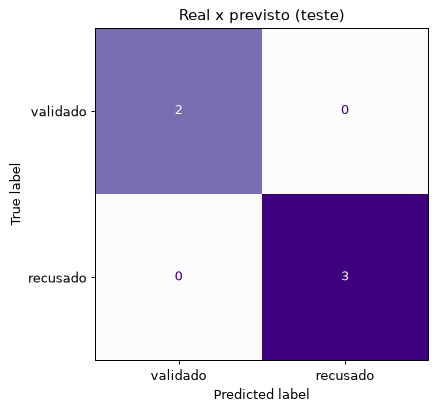

O que a árvore aprendeu:
|--- email_tem_nome <= 0.50
|   |--- numeros_email <= 1.00
|   |   |--- class: recusado
|   |--- numeros_email >  1.00
|   |   |--- class: recusado
|--- email_tem_nome >  0.50
|   |--- palavras_nome <= 1.50
|   |   |--- class: recusado
|   |--- palavras_nome >  1.50
|   |   |--- class: validado



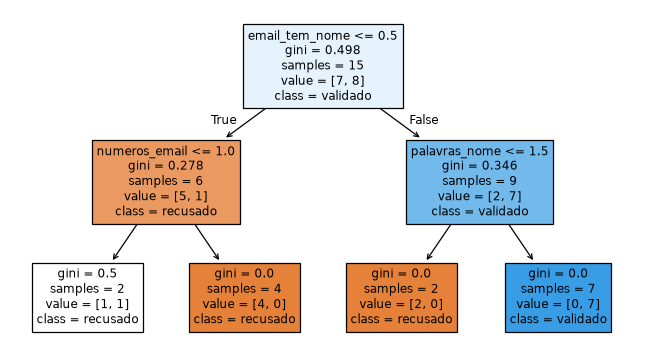

In [4]:
arvore = DecisionTreeClassifier(max_depth=2, random_state=42)
arvore.fit(X_treino, y_treino)
previsto = arvore.predict(X_teste)

print(f"Acurácia: {accuracy_score(y_teste, previsto):.1%}")

ordem = ["validado", "recusado"]
matriz = confusion_matrix(y_teste, previsto, labels=ordem)
print(pd.DataFrame(matriz, index=ordem, columns=ordem))

ConfusionMatrixDisplay(matriz, display_labels=ordem).plot(cmap="Purples", colorbar=False)
plt.title("Real x previsto (teste)")
plt.show()

print("O que a árvore aprendeu:")
print(export_text(arvore, feature_names=entradas))

plt.figure(figsize=(9, 5))
plot_tree(arvore, feature_names=entradas, class_names=list(arvore.classes_), filled=True)
plt.show()

### O que eu vi no resultado

- A acurácia deu **100%**: os 5 cadastros do teste (linhas 5, 8, 13, 14 e 17) foram previstos certo. Na matriz, 2 validados e 3 recusados, todos na diagonal.
- Mas **não dá para comemorar**: são só 5 casos, e eu montei os dados com um critério bem simples, então era fácil acertar. A professora falou disso na aula, e é o mesmo alerta do slide da matriz de confusão.
- A árvore aprendeu praticamente o meu critério:
  - se o e-mail **não tem** o nome da pessoa (`email_tem_nome <= 0.5`), ela diz `recusado`;
  - se tem, ela olha o nome: com **uma palavra só** (`palavras_nome <= 1.5`), `recusado`, e com mais de uma, `validado`.
- Do lado esquerdo ela ainda separou por `numeros_email`. Um dos grupos ficou com 2 cadastros, um validado (a linha 20) e um recusado, e como empatou a árvore escolheu `recusado`. Por isso os dois lados dão `recusado`.
- A **linha 20** (o e-mail de setor que foi validado) ficou no **treino**, e mesmo assim a árvore prevê `recusado` para ela. Com profundidade 2 e um caso só, ela não consegue aprender essa exceção.

## 5. Base de conhecimento e motor de inferência

Igual no exemplo da aula, fiz uma tabela 2 × 2: a previsão do modelo cruzada com o que o administrador informa.

| Regra | Previsão (modelo) | Vínculo confirmado (administrador) | O que fazer |
|:--:|:--:|:--:|:--|
| R1 | validado | sim | validar e escolher o perfil |
| R2 | validado | não | confirmar o vínculo antes de validar |
| R3 | recusado | sim | conferir os dados com a pessoa |
| R4 | recusado | não | recusar com o motivo |

**De onde tirei as regras:**

- R1 e R4 seguem o que o squad já implementou: `validar_cadastro` exige pelo menos um perfil (RN-26) e `recusar_cadastro` exige motivo (RN-36);
- R2 e R3 fui eu que pensei, para o administrador não decidir só pela previsão;
- o prazo de 30 dias vem de `DIAS_PARA_VALIDAR = 30` em `contas/services.py`. Ele não muda a regra, mas avisa quando o cadastro está perto de ser apagado.

In [5]:
regras = [
    {"id": "R1", "previsao": "validado", "vinculo_confirmado": True,
     "acao": "Validar o cadastro e escolher pelo menos um perfil (o Orientador já vem marcado)."},
    {"id": "R2", "previsao": "validado", "vinculo_confirmado": False,
     "acao": "Confirmar com a coordenação se a pessoa é da faculdade antes de validar."},
    {"id": "R3", "previsao": "recusado", "vinculo_confirmado": True,
     "acao": "Falar com a pessoa para conferir nome e e-mail antes de decidir."},
    {"id": "R4", "previsao": "recusado", "vinculo_confirmado": False,
     "acao": "Recusar informando o motivo (o cadastro é apagado e a pessoa recebe o motivo por e-mail)."},
]

def motor(previsao, vinculo_confirmado):
    for regra in regras:
        if regra["previsao"] == previsao and regra["vinculo_confirmado"] == vinculo_confirmado:
            return regra
    raise ValueError("Nenhuma regra serve para esses fatos.")

## 6. Juntando o modelo com o sistema especialista

In [6]:
DIAS_PARA_VALIDAR = 30   # o mesmo valor do squad 5 (RN-36)

def analisar_cadastro(palavras_nome, email_tem_nome, numeros_email, dias_na_fila, vinculo_confirmado):
    if palavras_nome < 1 or numeros_email < 0 or email_tem_nome not in (0, 1):
        raise ValueError("Confira os dados do cadastro.")
    if not isinstance(vinculo_confirmado, bool):
        raise ValueError("vinculo_confirmado tem que ser True ou False.")

    caso = pd.DataFrame([{"palavras_nome": palavras_nome, "email_tem_nome": email_tem_nome,
                          "numeros_email": numeros_email}])
    previsao = arvore.predict(caso)[0]          # 1) o modelo prevê
    regra = motor(previsao, vinculo_confirmado)  # 2) a previsão vira fato e o motor escolhe a regra

    dias_restantes = DIAS_PARA_VALIDAR - dias_na_fila
    if dias_restantes <= 5:
        prazo = f"Atenção: faltam {dias_restantes} dia(s) para o cadastro ser apagado automaticamente."
    else:
        prazo = f"Faltam {dias_restantes} dias para o prazo de 30 dias."

    return {
        "previsao": previsao,
        "regra": regra["id"],
        "recomendacao": regra["acao"],
        "por_que": f"previsão = {previsao}; vínculo confirmado = {vinculo_confirmado}",
        "prazo": prazo,
    }

## 7. Testando três cadastros novos
Nenhum deles está no dataset.

In [7]:
novos = [
    # (palavras do nome, e-mail tem nome?, números no e-mail, dias na fila, vínculo confirmado?)
    (3, 1, 0, 4,  True),
    (4, 1, 1, 12, False),
    (1, 0, 4, 27, False),
]
for i, cadastro in enumerate(novos, 1):
    print(f"\nCADASTRO {i}: {cadastro}")
    for chave, valor in analisar_cadastro(*cadastro).items():
        print(f"  {chave}: {valor}")


CADASTRO 1: (3, 1, 0, 4, True)
  previsao: validado
  regra: R1
  recomendacao: Validar o cadastro e escolher pelo menos um perfil (o Orientador já vem marcado).
  por_que: previsão = validado; vínculo confirmado = True
  prazo: Faltam 26 dias para o prazo de 30 dias.

CADASTRO 2: (4, 1, 1, 12, False)
  previsao: validado
  regra: R2
  recomendacao: Confirmar com a coordenação se a pessoa é da faculdade antes de validar.
  por_que: previsão = validado; vínculo confirmado = False
  prazo: Faltam 18 dias para o prazo de 30 dias.

CADASTRO 3: (1, 0, 4, 27, False)
  previsao: recusado
  regra: R4
  recomendacao: Recusar informando o motivo (o cadastro é apagado e a pessoa recebe o motivo por e-mail).
  por_que: previsão = recusado; vínculo confirmado = False
  prazo: Atenção: faltam 3 dia(s) para o cadastro ser apagado automaticamente.


### Os três casos

- **Cadastro 1:** nome com 3 palavras, e-mail com o nome, e o administrador já confirmou o vínculo. O modelo prevê `validado` e a **R1** manda validar e escolher o perfil.
- **Cadastro 2:** os dados parecem bons, e o modelo prevê `validado`, mas o vínculo ainda não foi confirmado. A **R2** manda confirmar com a coordenação antes. Faltam 18 dias, então dá tempo.
- **Cadastro 3:** nome com uma palavra e e-mail sem nome, e o modelo prevê `recusado`. Sem vínculo confirmado, a **R4** manda recusar com motivo. O aviso de prazo apareceu porque está há 27 dias na fila e faltam só 3 para ele ser apagado sozinho.

## 8. Mudando só o que o administrador informa
Peguei o cadastro 2 e troquei só o `vinculo_confirmado` de `False` para `True`. Os dados do cadastro são os mesmos.

In [8]:
antes = analisar_cadastro(4, 1, 1, 12, False)
depois = analisar_cadastro(4, 1, 1, 12, True)
print("previsão:", antes["previsao"], "->", depois["previsao"])
print("regra:   ", antes["regra"], "->", depois["regra"])
print("antes: ", antes["recomendacao"])
print("depois:", depois["recomendacao"])

previsão: validado -> validado
regra:    R2 -> R1
antes:  Confirmar com a coordenação se a pessoa é da faculdade antes de validar.
depois: Validar o cadastro e escolher pelo menos um perfil (o Orientador já vem marcado).


> **Obs.:** A previsão não mudou, porque os dados são os mesmos. Quem mudou a recomendação foi o **sistema especialista**, por causa do fato que o administrador informou.

## 9. Erros, limitações e cuidados

- **Poucos dados e simulados:** 20 cadastros e só 5 no teste. Cada erro tira 20 pontos da acurácia, então o número sozinho não diz muito.
- **Exemplo pouco representado:** só tem **um** e-mail de setor (a linha 20). O modelo quase não tem como aprender esse caso, e por isso a R3 existe: quando o vínculo está confirmado, a pessoa confere antes de recusar.
- **Viés:** nome com uma palavra só não quer dizer que a pessoa não é da faculdade. Tem gente com nome curto, e tem pessoa estrangeira que registra o nome diferente. Se eu usasse isso para recusar direto, o sistema ia ser injusto com essas pessoas. Por isso **a decisão é sempre do administrador**.
- **Dados pessoais (LGPD):** eu não uso o nome nem o e-mail em si, só contagens. O próprio squad já apaga cadastro não validado em 30 dias para não guardar dado sem finalidade (RN-36).
- **O modelo não sabe o que não está nas colunas:** ele não sabe se a pessoa é professora de verdade. Só o administrador consegue confirmar isso.

## Perguntas da aula

- **Qual parte aprende com os dados?** A árvore de decisão (`arvore.fit`).
- **Qual parte aplica as regras humanas?** A função `motor`, com as regras R1 a R4.
- **Por que dificuldade em lógica não estava nos atributos no exemplo da professora?** Porque era um fato que o usuário informava. No meu caso é a mesma coisa com o `vinculo_confirmado`: ele não entra no modelo, entra direto nas regras.
- **100% em poucos casos é suficiente?** Não. Com 5 casos de teste, acertar tudo pode ser só sorte da divisão.

## Referências
- IBM. Guia de Aprendizado de Máquina e Aprendizado supervisionado.
- scikit-learn: `DecisionTreeClassifier` e `train_test_split`.
- Notebook e slides da Aula 13, Profa. Kadidja Valéria.
- Documentação do squad 5: `docs/requirements.md` (RN-03, RN-25, RN-26, RN-36) e `contas/services.py`.